# SANOS-Strike + EKF Evaluation

Online SANOS EKF in **absolute strike space** (σ* = 0).  
Density: `q = Q⁻¹(x,T) \ q̄₀` via SANOS tri-diagonal.  
Observation: `h = Σ qᵢ (Kᵢ − K_market)⁺` (undiscounted absolute call).  

Sections: data loading → sanity checks → fit → in-sample → OOS → density diagnostics → state evolution.

In [1]:
import os
import sys
from datetime import date

import jax.numpy as jnp
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from scipy.stats import norm as sp_norm

project_root = "/Users/elie/Documents/GitHub/quant_data/"
kf_dir = os.path.join(project_root, "personal", "Kalman_filter_spline")
for p in [project_root, kf_dir]:
    if p not in sys.path:
        sys.path.insert(0, p)

os.environ.setdefault("QUANTDATA_RAW_DATA", "/quantdata/raw")

from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from personal.SANOS_KF_Strike.sanos_kf_strike import (
    SanosKFStrikeConfig,
    _density_from_state,
    _q_bar_0_from_strikes,
    run_sanos_kf_strike,
)
from quantdata.massive.client import MassiveClient

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Load data

In [2]:
TICKER = "SPY"
TRADE_DATE = date(2024, 1, 3)
MIN_TRADES = 100

In [3]:
df_tickers = pl.read_csv(os.path.join(project_root, "personal", "spy_options_tickers.csv"))

client = MassiveClient()
df_spy = client.fetch_trades(TICKER, TRADE_DATE)

df_quotes_all, df_trades_all = build_iv_observations(
    df_tickers, TRADE_DATE, df_spy, min_trades=MIN_TRADES
)

print(f"quotes: {len(df_quotes_all):,}   trades: {len(df_trades_all):,}")
print("quote columns:", df_quotes_all.columns)

Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105P00462500: 17 bad quotes
Expiry 2024-01-05: implied forward from 13 strike(s)
quotes: 2,115,510   trades: 74,099
quote columns: ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'discount_factor']


In [4]:
df_quotes_all

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null
…,…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,469.0,true,-0.000117,0.005447,0.134535,0.134132,0.134856,1.3110e-7,1.88,1.89,469.055,1.0
2024-01-03 16:14:59.884593152 EST,474.0,false,0.010487,0.005447,0.138451,0.132675,0.144803,0.000037,5.28,5.38,469.055,1.0
2024-01-03 16:14:59.884598272 EST,472.0,false,0.006259,0.005447,0.13324,0.131454,0.136743,0.000007,3.66,3.72,469.055,1.0


## Config — absolute strike grid

In [5]:
# Derive anchor grid from the unique observed strikes in the data
fwds_obs = df_quotes_all["forward"].to_numpy().astype(float)
ks_obs = df_quotes_all["log_moneyness"].to_numpy().astype(float)
K_abs_obs = fwds_obs * np.exp(ks_obs)

valid = np.isfinite(K_abs_obs) & np.isfinite(fwds_obs) & (fwds_obs > 0)
strike_round = 1.0  # SPY/SPX: integer strikes
K_rounded = np.round(K_abs_obs[valid] / strike_round) * strike_round
anchor_Ks = np.sort(np.unique(K_rounded))

print(f"Anchor grid: {len(anchor_Ks)} strikes  [{anchor_Ks[0]:.0f}, {anchor_Ks[-1]:.0f}]")
print("anchors:", anchor_Ks)

Anchor grid: 25 strikes  [450, 480]
anchors: [450. 454. 458. 459. 460. 461. 462. 463. 464. 465. 466. 467. 468. 469.
 470. 471. 472. 473. 474. 475. 476. 477. 478. 479. 480.]


In [94]:
cfg = SanosKFStrikeConfig(
    Sigma_sq_init=0.01,  # initial (Σᵢ)² ≈ 20% vol squared
    Q_scale_dlv_sq=1e-6,  # process noise per trading day
    P0_scale=1e-2,
    calls_only=True,
)

In [95]:
df_quotes_exp = df_quotes_all.drop("discount_factor", strict=False)
df_trades_exp = df_trades_all.drop("discount_factor", strict=False)

## Sanity checks

F_0 = 470.4300
q_bar_0 sum  = 1.000000  (expect 1.0)
q_bar_0 mean = 470.4300  (expect ≈ F_0 = 470.4300)


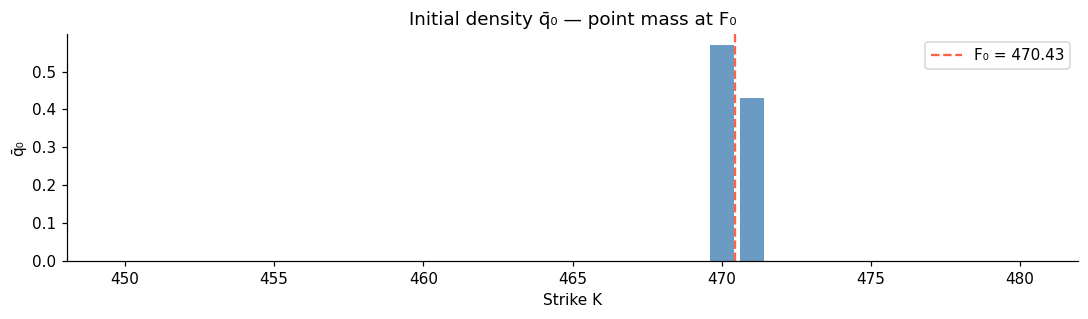

In [96]:
# --- q_bar_0 check ---
F_0 = float(df_quotes_exp["forward"][0])
q_bar_0_np = _q_bar_0_from_strikes(anchor_Ks, F_0)

print(f"F_0 = {F_0:.4f}")
print(f"q_bar_0 sum  = {q_bar_0_np.sum():.6f}  (expect 1.0)")
print(f"q_bar_0 mean = {(q_bar_0_np * anchor_Ks).sum():.4f}  (expect ≈ F_0 = {F_0:.4f})")

bar_w = 0.8 * np.min(np.diff(anchor_Ks))
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(anchor_Ks, q_bar_0_np, width=bar_w, color="steelblue", alpha=0.8)
ax.axvline(F_0, color="tomato", lw=1.5, ls="--", label=f"F₀ = {F_0:.2f}")
ax.set_xlabel("Strike K")
ax.set_ylabel("q̄₀")
ax.set_title("Initial density q̄₀ — point mass at F₀")
ax.legend()
plt.tight_layout()
plt.show()

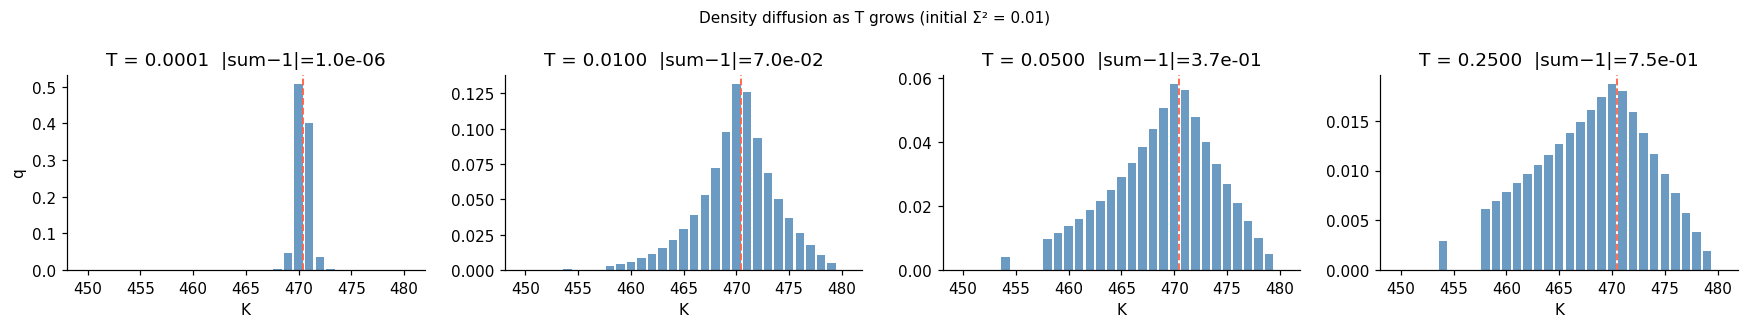

In [97]:
# --- Density diffusion check: q should spread as T grows ---
n_state_sanity = len(anchor_Ks) - 2
x_init = np.full(n_state_sanity, cfg.Sigma_sq_init)
q_bar_0_jax = jnp.array(q_bar_0_np)
ak_jax = jnp.array(anchor_Ks)

bar_w = 0.8 * np.min(np.diff(anchor_Ks))
T_vals = [1e-4, 1e-2, 0.05, 0.25]
fig, axes = plt.subplots(1, len(T_vals), figsize=(16, 3), sharey=False)
for ax, T_v in zip(axes, T_vals):
    q_v = np.array(_density_from_state(jnp.array(x_init), ak_jax, T_v, q_bar_0_jax))
    ax.bar(anchor_Ks, q_v, width=bar_w, color="steelblue", alpha=0.8)
    ax.axvline(F_0, color="tomato", lw=1.2, ls="--")
    ax.set_title(f"T = {T_v:.4f}  |sum−1|={abs(q_v.sum() - 1):.1e}")
    ax.set_xlabel("K")
    if ax is axes[0]:
        ax.set_ylabel("q")
fig.suptitle(f"Density diffusion as T grows (initial Σ² = {cfg.Sigma_sq_init})", fontsize=10)
plt.tight_layout()
plt.show()

In [98]:
# --- Jacobian finite-difference check ---
import jax

from personal.SANOS_KF_Strike.sanos_kf_strike import _jac_fn_strike, _obs_jit_strike

T_test = 0.05
K_test = float(anchor_Ks[len(anchor_Ks) // 2])  # ATM-ish
x_test = jnp.array(x_init)

H_auto = np.array(_jac_fn_strike(x_test, ak_jax, K_test, T_test, q_bar_0_jax))

eps = 1e-5
H_fd = np.zeros_like(H_auto)
for j in range(len(x_init)):
    e = np.zeros(len(x_init))
    e[j] = eps
    hp = float(_obs_jit_strike(x_test + e, ak_jax, K_test, T_test, q_bar_0_jax))
    hm = float(_obs_jit_strike(x_test - e, ak_jax, K_test, T_test, q_bar_0_jax))
    H_fd[j] = (hp - hm) / (2 * eps)

max_err = np.max(np.abs(H_auto - H_fd))
print(f"Max Jacobian error (auto vs FD): {max_err:.2e}  (expect < 1e-6)")

Max Jacobian error (auto vs FD): 6.78e-05  (expect < 1e-6)


## Run SANOS-Strike EKF

In [99]:
df_q, df_t, df_state = run_sanos_kf_strike(
    df_quotes_exp, df_trades_exp, cfg, return_state=True, anchor_Ks=anchor_Ks
)

print("quote result columns :", df_q.columns)
print("trade result columns :", df_t.columns)
print(f"Finite model prices  : {df_q['sanos_kf_price'].is_finite().sum()}/{len(df_q)}")
print(f"Finite model IVs     : {df_q['sanos_kf_iv'].is_finite().sum()}/{len(df_q)}")
print(f"Finite trade matches : {df_t['sanos_kf_matched'].is_finite().sum()}/{len(df_t)}")

quote result columns : ['ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'R_iv', 'bid_price', 'ask_price', 'forward', 'sanos_kf_price', 'sanos_kf_iv']
trade result columns : ['ts_ns', 'quote_ts_ns', 'strike', 'is_call', 'log_moneyness', 'T', 'observed_iv', 'bid_iv', 'ask_iv', 'bid_price', 'ask_price', 'forward', 'ts_ns_right', 'sanos_kf_matched', 'trade_residual']
Finite model prices  : 952778/2115510
Finite model IVs     : 910860/2115510
Finite trade matches : 71704/74099


---
## Section 1 — In-Sample Fit

### 1a. Call price snapshots at 5 intraday percentiles

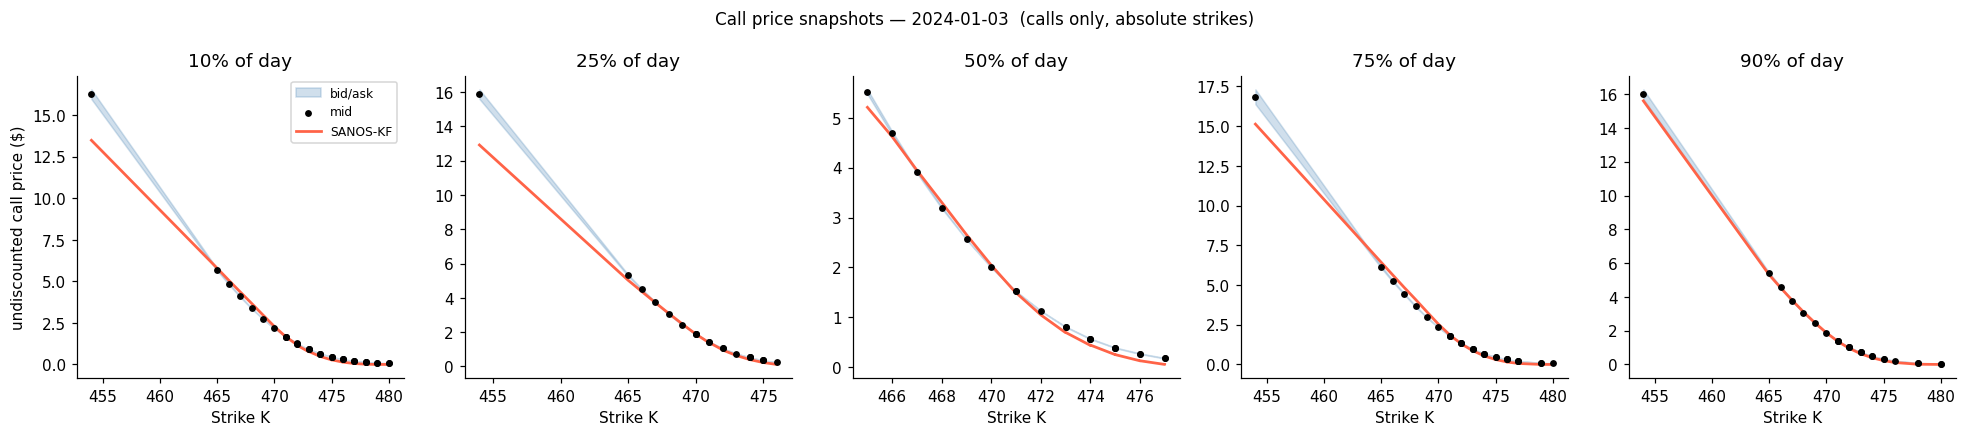

In [100]:
# Absolute strikes: K = F * exp(k)
df_calls_p = (
    df_q.filter(pl.col("is_call") & pl.col("sanos_kf_price").is_finite())
    .with_columns((pl.col("forward") * (pl.col("log_moneyness").exp())).alias("K_abs"))
    .filter((pl.col("K_abs") >= anchor_Ks[0]) & (pl.col("K_abs") <= anchor_Ks[-1]))
    .sort("ts_ns")
)

ts_vals = df_calls_p["ts_ns"].cast(pl.Int64).to_numpy()
ts_min, ts_max = ts_vals.min(), ts_vals.max()
percentiles = [0.10, 0.25, 0.50, 0.75, 0.90]
snap_ts = [int(ts_min + p * (ts_max - ts_min)) for p in percentiles]
WINDOW_NS = 5 * int(1e9)

fig, axes = plt.subplots(1, len(percentiles), figsize=(18, 4), sharey=False)
for ax, ts_snap, pct in zip(axes, snap_ts, percentiles):
    mask = np.abs(ts_vals - ts_snap) < WINDOW_NS
    df_snap = df_calls_p.filter(pl.Series(mask))
    if df_snap.is_empty():
        ax.set_title(f"{pct:.0%}")
        continue

    agg_cols = [
        pl.col("bid_price").mean(),
        pl.col("ask_price").mean(),
        pl.col("sanos_kf_price").mean(),
    ]
    if "discount_factor" in df_snap.columns:
        agg_cols.append(pl.col("discount_factor").mean())
    df_snap = df_snap.group_by("K_abs").agg(agg_cols).sort("K_abs")

    Ks = df_snap["K_abs"].to_numpy()
    bid = df_snap["bid_price"].to_numpy()
    ask = df_snap["ask_price"].to_numpy()
    mdl = df_snap["sanos_kf_price"].to_numpy()
    df_col = np.ones(len(Ks))
    if "discount_factor" in df_snap.columns:
        df_col = df_snap["discount_factor"].to_numpy()
    bid_u = bid / df_col
    ask_u = ask / df_col

    ax.fill_between(Ks, bid_u, ask_u, alpha=0.25, color="steelblue", label="bid/ask")
    ax.scatter(Ks, (bid_u + ask_u) / 2, s=12, color="black", zorder=3, label="mid")
    ax.plot(Ks, mdl, color="tomato", lw=1.8, label="SANOS-KF")
    ax.set_title(f"{pct:.0%} of day")
    ax.set_xlabel("Strike K")
    if ax is axes[0]:
        ax.set_ylabel("undiscounted call price ($)")
        ax.legend(fontsize=8)

fig.suptitle(f"Call price snapshots — {TRADE_DATE}  (calls only, absolute strikes)", fontsize=11)
plt.tight_layout()
plt.show()

In [101]:
Ks

array([454., 465., 466., 467., 468., 469., 470., 471., 471., 471., 472.,
       472., 472., 473., 473., 473., 474., 474., 475., 475., 476., 478.,
       478., 480., 480.])

### 1b. IV smile snapshots at 5 intraday percentiles

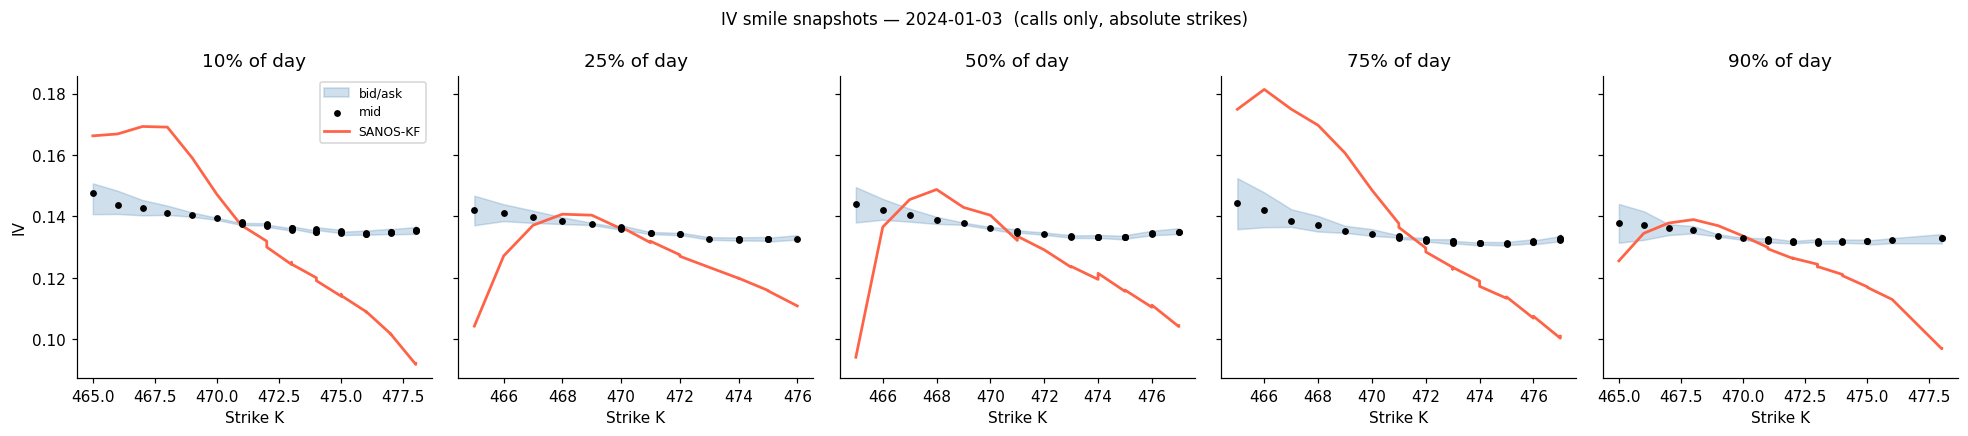

In [102]:
df_calls_iv = (
    df_q.filter(
        pl.col("is_call") & pl.col("sanos_kf_iv").is_finite() & pl.col("observed_iv").is_finite()
    )
    .with_columns((pl.col("forward") * (pl.col("log_moneyness").exp())).alias("K_abs"))
    .sort("ts_ns")
)

ts_vals = df_calls_iv["ts_ns"].cast(pl.Int64).to_numpy()
ts_min, ts_max = ts_vals.min(), ts_vals.max()
snap_ts = [int(ts_min + p * (ts_max - ts_min)) for p in percentiles]

fig, axes = plt.subplots(1, len(percentiles), figsize=(18, 4), sharey=True)
for ax, ts_snap, pct in zip(axes, snap_ts, percentiles):
    mask = np.abs(ts_vals - ts_snap) < WINDOW_NS
    df_snap = df_calls_iv.filter(pl.Series(mask)).unique(subset=["K_abs"], keep="last")
    if df_snap.is_empty():
        ax.set_title(f"{pct:.0%}")
        continue
    df_snap = df_snap.sort("K_abs")
    Ks = df_snap["K_abs"].to_numpy()
    mid = df_snap["observed_iv"].to_numpy()
    bid = df_snap["bid_iv"].to_numpy()
    ask = df_snap["ask_iv"].to_numpy()
    mdl = df_snap["sanos_kf_iv"].to_numpy()

    ax.fill_between(Ks, bid, ask, alpha=0.25, color="steelblue", label="bid/ask")
    ax.scatter(Ks, mid, s=12, color="black", zorder=3, label="mid")
    ax.plot(Ks, mdl, color="tomato", lw=1.8, label="SANOS-KF")
    ax.set_title(f"{pct:.0%} of day")
    ax.set_xlabel("Strike K")
    if ax is axes[0]:
        ax.set_ylabel("IV")
        ax.legend(fontsize=8)

fig.suptitle(f"IV smile snapshots — {TRADE_DATE}  (calls only, absolute strikes)", fontsize=11)
plt.tight_layout()
plt.show()

In [103]:
Ks.shape

(22,)

In [104]:
mdl.shape

(22,)

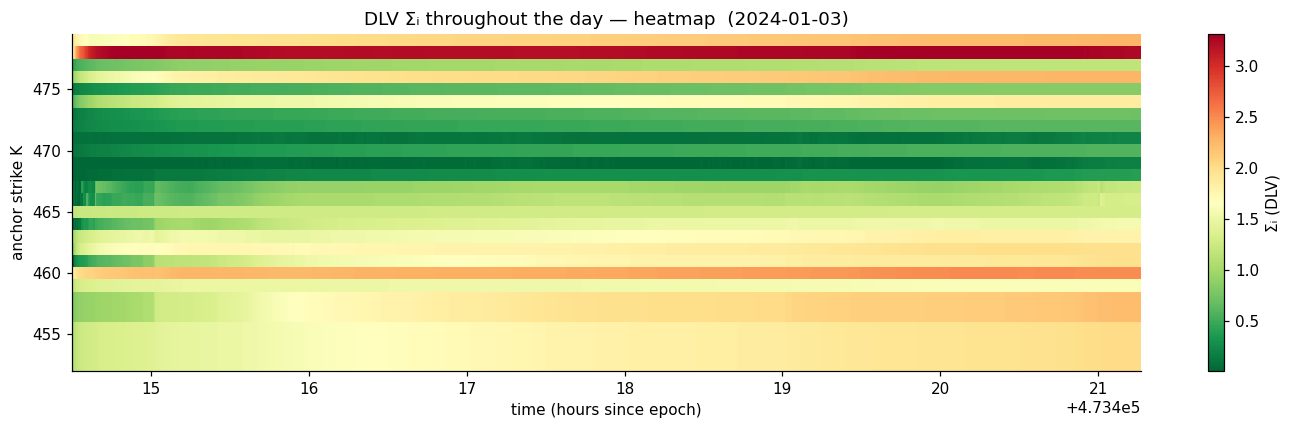

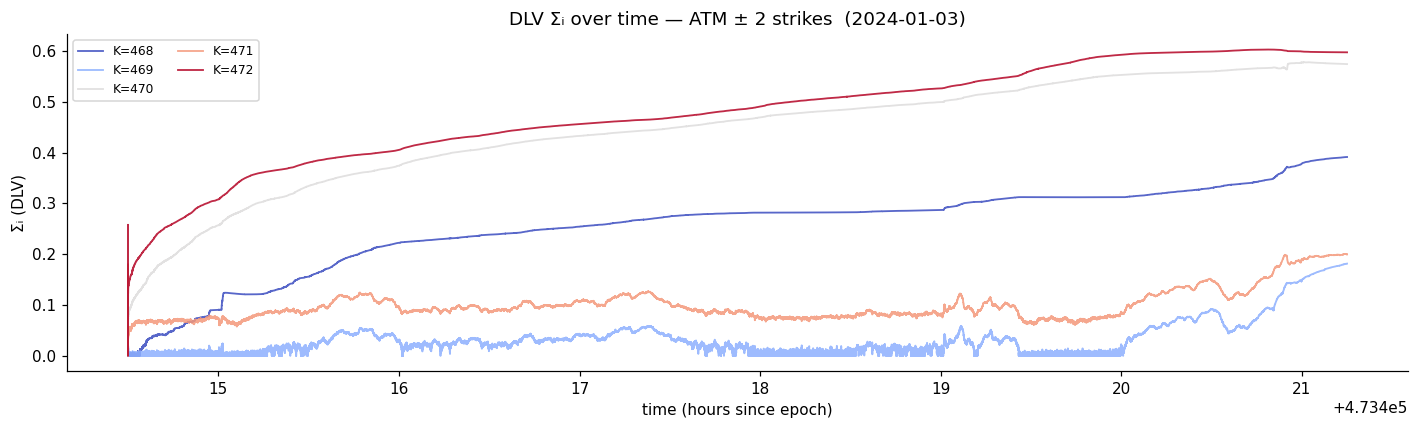

In [105]:
### 1b.5  DLV (Σᵢ) evolution throughout the day

_n_state = len(anchor_Ks) - 2

_x_cols = [f"x_{j}" for j in range(_n_state)]
_X = df_state.select(_x_cols).to_numpy()  # (N_obs, n_state)
_ts_h = df_state["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600
_Sigma = np.sqrt(np.maximum(_X, 0))  # (Σᵢ), not squared
_interior_Ks = anchor_Ks[1:-1]  # n_state interior anchors

# ── A: heatmap (all strikes × time) ──────────────────────────────────────────
stride = max(1, len(_X) // 800)
fig, ax = plt.subplots(figsize=(13, 4))
im = ax.pcolormesh(
    _ts_h[::stride],
    _interior_Ks,
    _Sigma[::stride].T,
    cmap="RdYlGn_r",
    vmin=np.nanpercentile(_Sigma, 1),
    vmax=np.nanpercentile(_Sigma, 99),
    shading="auto",
)
plt.colorbar(im, ax=ax, label="Σᵢ (DLV)")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("anchor strike K")
ax.set_title(f"DLV Σᵢ throughout the day — heatmap  ({TRADE_DATE})")
plt.tight_layout()
plt.show()

# ── B: line plot for ~5 representative strikes (ATM ± 2) ─────────────────────
F_approx = float(df_quotes_exp["forward"][0])
atm_idx = int(np.argmin(np.abs(_interior_Ks - F_approx)))
n_lines = 5
sel_idx = np.clip(
    np.linspace(atm_idx - n_lines // 2, atm_idx + n_lines // 2, n_lines, dtype=int),
    0,
    len(_interior_Ks) - 1,
)

fig, ax = plt.subplots(figsize=(13, 4))
cmap_lines = plt.cm.coolwarm(np.linspace(0, 1, len(sel_idx)))
for color, idx in zip(cmap_lines, sel_idx):
    lbl = f"K={_interior_Ks[idx]:.0f}"
    ax.plot(_ts_h, _Sigma[:, idx], lw=1.2, alpha=0.85, color=color, label=lbl)
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("Σᵢ (DLV)")
ax.set_title(f"DLV Σᵢ over time — ATM ± {n_lines // 2} strikes  ({TRADE_DATE})")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

### 1c. Innovation time series

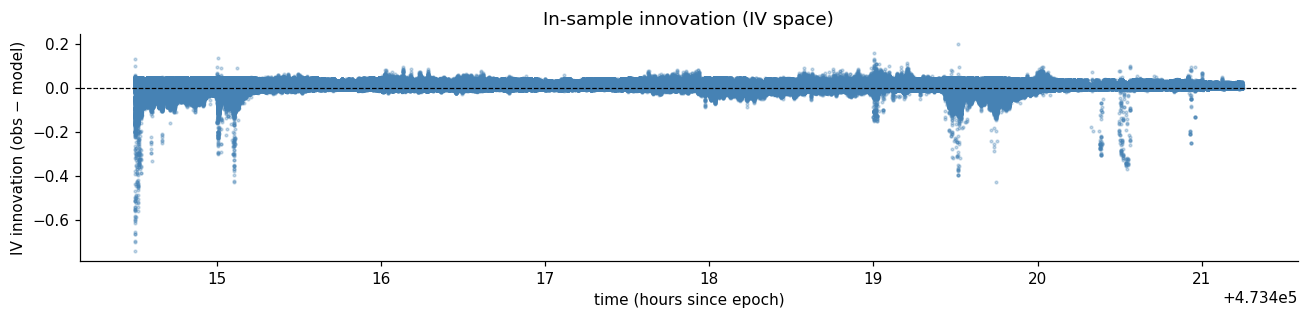

Innovation  mean=0.0005  std=0.0238


In [106]:
df_innov = df_calls_iv.with_columns(
    (pl.col("observed_iv") - pl.col("sanos_kf_iv")).alias("innov")
).filter(pl.col("innov").is_finite())

ts_h = df_innov["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600
innov = df_innov["innov"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.scatter(ts_h, innov, s=3, alpha=0.3, color="steelblue")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("IV innovation (obs − model)")
ax.set_title("In-sample innovation (IV space)")
plt.tight_layout()
plt.show()

print(f"Innovation  mean={innov.mean():.4f}  std={innov.std():.4f}")

### 1d. % inside bid-ask band (rolling 1-min)

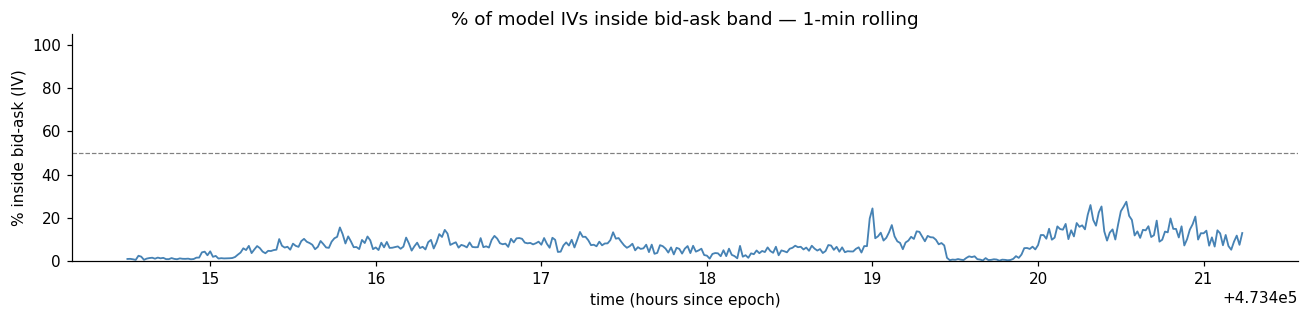

Overall % inside: 7.4%


In [107]:
df_inside = df_calls_iv.with_columns(
    ((pl.col("sanos_kf_iv") >= pl.col("bid_iv")) & (pl.col("sanos_kf_iv") <= pl.col("ask_iv")))
    .cast(pl.Float64)
    .alias("inside")
).filter(pl.col("bid_iv").is_finite() & pl.col("ask_iv").is_finite())

BUCKET_NS = int(60e9)
df_rolling = (
    df_inside.with_columns(
        (pl.col("ts_ns").cast(pl.Int64) // BUCKET_NS * BUCKET_NS).alias("bucket")
    )
    .group_by("bucket")
    .agg(pl.col("inside").mean().alias("pct_inside"))
    .sort("bucket")
)

t_buckets = df_rolling["bucket"].to_numpy() / 1e9 / 3600
pct = df_rolling["pct_inside"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_buckets, pct * 100, color="steelblue", lw=1.2)
ax.axhline(50, color="gray", lw=0.8, ls="--")
ax.set_ylim(0, 105)
ax.set_ylabel("% inside bid-ask (IV)")
ax.set_xlabel("time (hours since epoch)")
ax.set_title("% of model IVs inside bid-ask band — 1-min rolling")
plt.tight_layout()
plt.show()

print(f"Overall % inside: {df_inside['inside'].mean() * 100:.1f}%")

---
## Section 2 — OOS Trade Evaluation

### 2a. Trade residual histogram

Trades: 71,704   RMSE=0.0194   Bias=-0.0016   MAE=0.0113  (IV units)


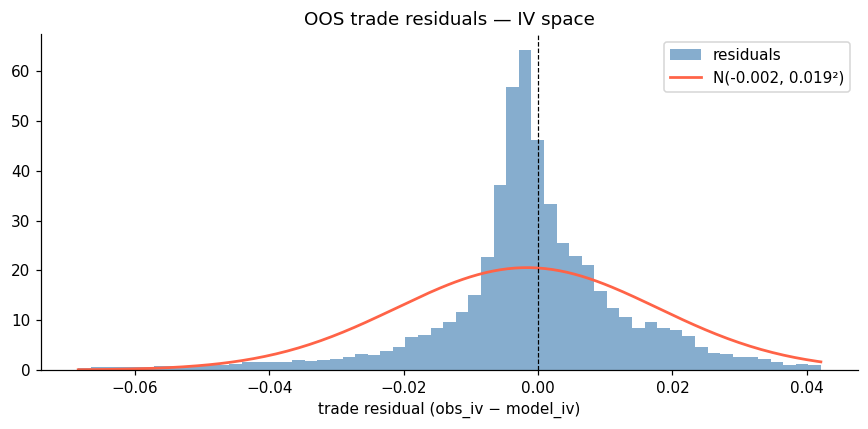

In [108]:
df_tc = df_t.filter(pl.col("trade_residual").is_finite() & pl.col("sanos_kf_matched").is_finite())
resid = df_tc["trade_residual"].to_numpy()

rmse = np.sqrt(np.mean(resid**2))
bias = np.mean(resid)
mae = np.mean(np.abs(resid))
print(f"Trades: {len(resid):,}   RMSE={rmse:.4f}   Bias={bias:.4f}   MAE={mae:.4f}  (IV units)")

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(np.percentile(resid, 1), np.percentile(resid, 99), 60)
ax.hist(resid, bins=bins, density=True, alpha=0.65, color="steelblue", label="residuals")
xg = np.linspace(bins[0], bins[-1], 200)
ax.plot(
    xg, sp_norm.pdf(xg, bias, rmse), color="tomato", lw=1.8, label=f"N({bias:.3f}, {rmse:.3f}²)"
)
ax.axvline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("trade residual (obs_iv − model_iv)")
ax.set_title("OOS trade residuals — IV space")
ax.legend()
plt.tight_layout()
plt.show()

### 2b. Residual vs absolute strike

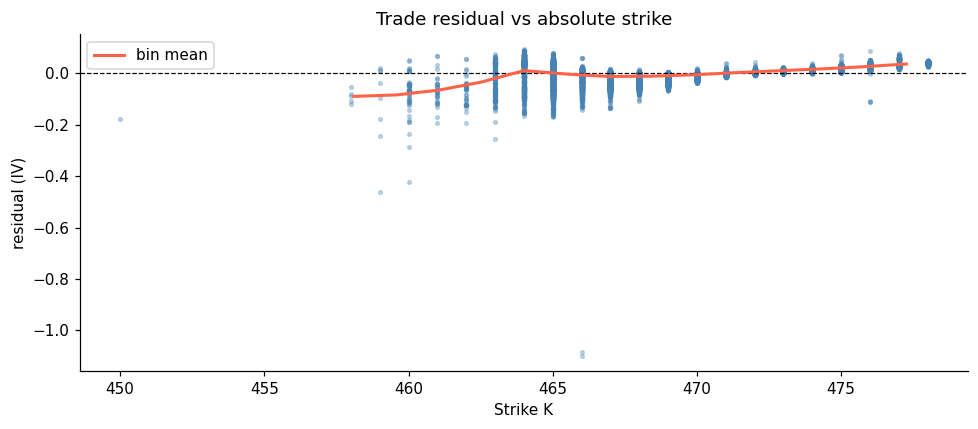

In [109]:
K_trades = (df_tc["forward"] * df_tc["log_moneyness"].exp()).to_numpy()

fig, ax = plt.subplots(figsize=(9, 4))
ax.scatter(K_trades, resid, s=6, alpha=0.3, color="steelblue")
ax.axhline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("Strike K")
ax.set_ylabel("residual (IV)")
ax.set_title("Trade residual vs absolute strike")

bins_K = np.linspace(K_trades.min(), K_trades.max(), 20)
idx = np.digitize(K_trades, bins_K)
bin_means = [
    resid[idx == i].mean() if (idx == i).sum() > 0 else np.nan for i in range(1, len(bins_K))
]
ax.plot(0.5 * (bins_K[:-1] + bins_K[1:]), bin_means, color="tomato", lw=2, label="bin mean")
ax.legend()
plt.tight_layout()
plt.show()

### 2c. Rolling RMSE over time

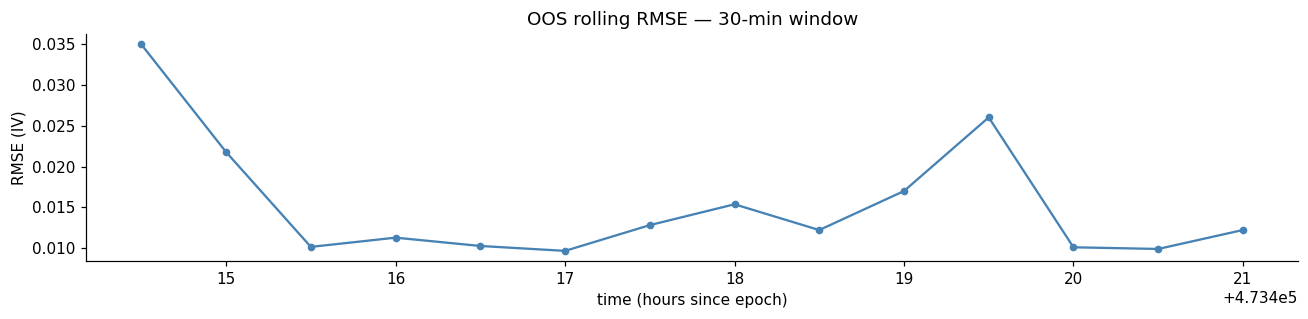

In [110]:
ROLL_NS = int(30 * 60e9)

df_roll_t = (
    df_tc.with_columns((pl.col("ts_ns").cast(pl.Int64) // ROLL_NS * ROLL_NS).alias("bucket"))
    .group_by("bucket")
    .agg(
        (pl.col("trade_residual") ** 2).mean().sqrt().alias("rmse"),
        pl.len().alias("n"),
    )
    .sort("bucket")
    .filter(pl.col("n") >= 3)
)

t_roll = df_roll_t["bucket"].to_numpy() / 1e9 / 3600
rmse_roll = df_roll_t["rmse"].to_numpy()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t_roll, rmse_roll, color="steelblue", lw=1.5, marker="o", ms=4)
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("RMSE (IV)")
ax.set_title("OOS rolling RMSE — 30-min window")
plt.tight_layout()
plt.show()

---
## Section 3 — Density Diagnostics

For each saved state x, recompute q via the SANOS solve and track health metrics.

In [111]:
import jax

n_state = len(anchor_Ks) - 2
x_cols = [f"x_{j}" for j in range(n_state)]
X = df_state.select(x_cols).to_numpy()  # (N_quotes, n_state)
ts_state = df_state["ts_ns"].cast(pl.Int64).to_numpy() / 1e9 / 3600
T_arr = df_q["T"].to_numpy().astype(float)

ak_jax = jnp.array(anchor_Ks)
q_bar_0_jax = jnp.array(_q_bar_0_from_strikes(anchor_Ks, float(df_q["forward"][0])))

# Valid rows: finite state + finite positive T
valid = np.isfinite(X).all(axis=1) & np.isfinite(T_arr) & (T_arr > 0)


# Batch-compute all densities with vmap (one compiled pass over the full history)
def _q_from_state(x, T):
    return _density_from_state(x, ak_jax, T, q_bar_0_jax)


Q_arr_jax = jax.jit(jax.vmap(_q_from_state))(jnp.array(X), jnp.array(T_arr))

# Metrics — vectorised over the time axis
_neg_mass = jnp.maximum(0.0, -Q_arr_jax).sum(axis=1)
_bdy_mass = Q_arr_jax[:, 0] + Q_arr_jax[:, -1]
_q_clip = jnp.maximum(Q_arr_jax, 1e-15)
_entropy = -(_q_clip * jnp.log(_q_clip)).sum(axis=1)
_mart_res = jnp.abs(Q_arr_jax @ ak_jax - (q_bar_0_jax * ak_jax).sum())

# Convert to numpy; mask rows where state was NaN (skipped quotes)
Q_arr = np.where(valid[:, None], np.array(Q_arr_jax), np.nan)
neg_mass = np.where(valid, np.array(_neg_mass), np.nan)
bdy_mass = np.where(valid, np.array(_bdy_mass), np.nan)
entropy = np.where(valid, np.array(_entropy), np.nan)
mart_resid = np.where(valid, np.array(_mart_res), np.nan)

print(f"Negative mass  mean={np.nanmean(neg_mass):.2e}  max={np.nanmax(neg_mass):.2e}")
print(f"Boundary mass  mean={np.nanmean(bdy_mass):.4f}")
print(f"Martingale resid  mean={np.nanmean(mart_resid):.2e}  max={np.nanmax(mart_resid):.2e}")

Negative mass  mean=0.00e+00  max=0.00e+00
Boundary mass  mean=0.0000
Martingale resid  mean=8.72e+01  max=1.50e+03


### 3a–3d. Density metrics over time

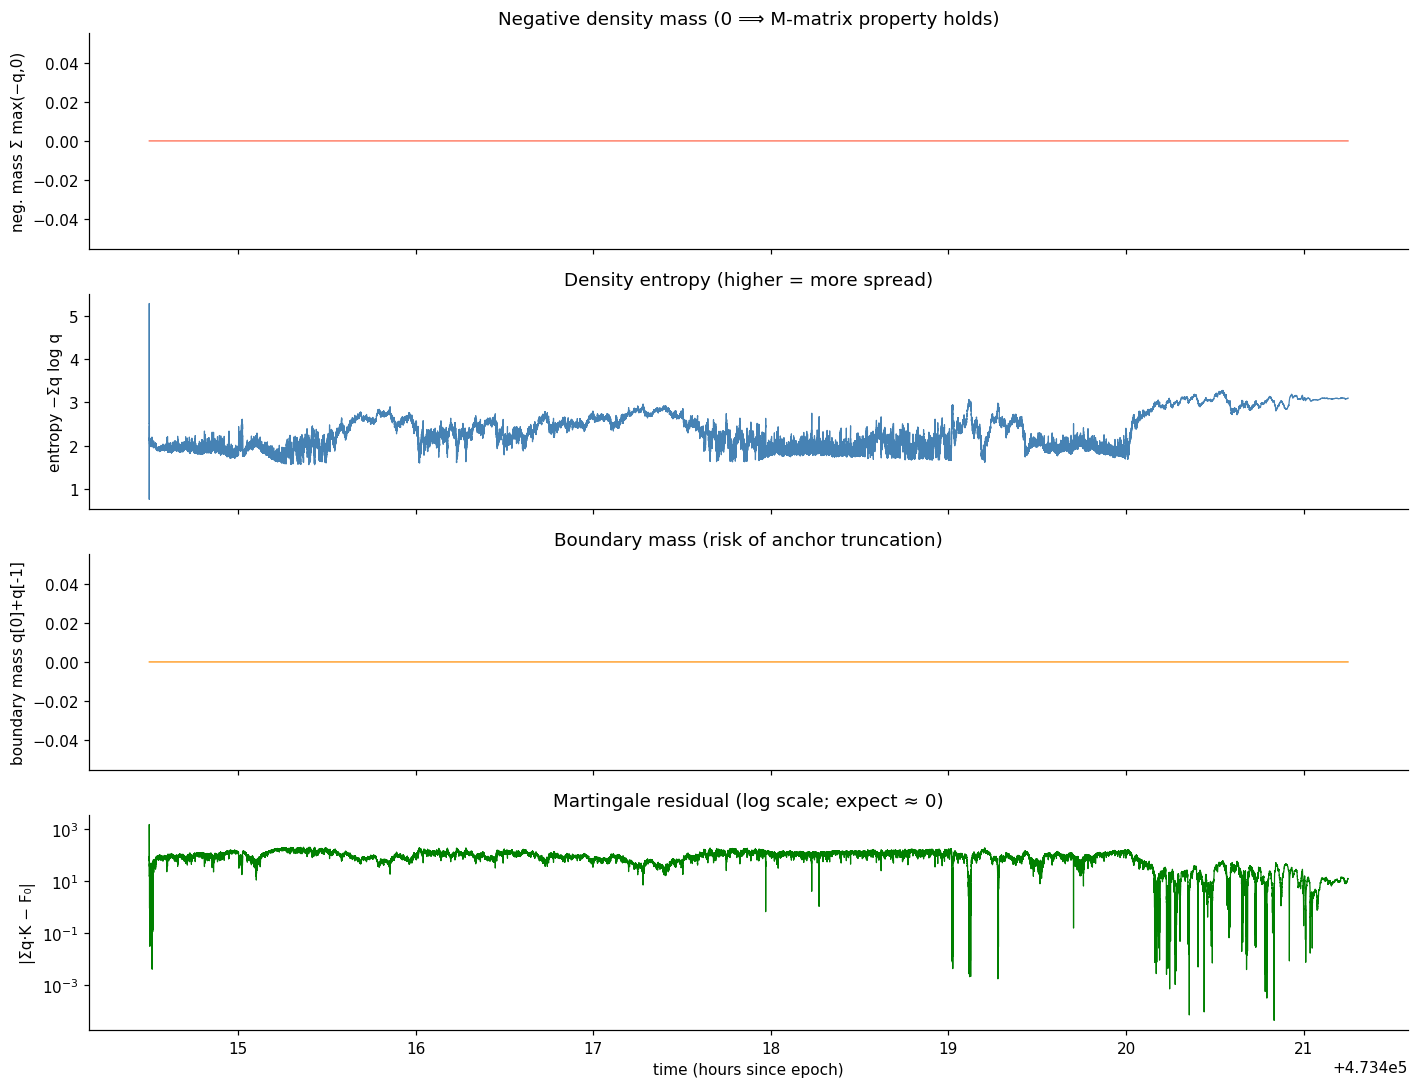

In [112]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)

axes[0].plot(ts_state, neg_mass, color="tomato", lw=0.8)
axes[0].set_ylabel("neg. mass Σ max(−q,0)")
axes[0].set_title("Negative density mass (0 ⟹ M-matrix property holds)")

axes[1].plot(ts_state, entropy, color="steelblue", lw=0.8)
axes[1].set_ylabel("entropy −Σq log q")
axes[1].set_title("Density entropy (higher = more spread)")

axes[2].plot(ts_state, bdy_mass, color="darkorange", lw=0.8)
axes[2].set_ylabel("boundary mass q[0]+q[-1]")
axes[2].set_title("Boundary mass (risk of anchor truncation)")

axes[3].semilogy(ts_state, np.maximum(mart_resid, 1e-15), color="green", lw=0.8)
axes[3].set_ylabel("|Σq·K − F₀|")
axes[3].set_xlabel("time (hours since epoch)")
axes[3].set_title("Martingale residual (log scale; expect ≈ 0)")

for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### 3e. Density snapshots at 4 intraday timestamps

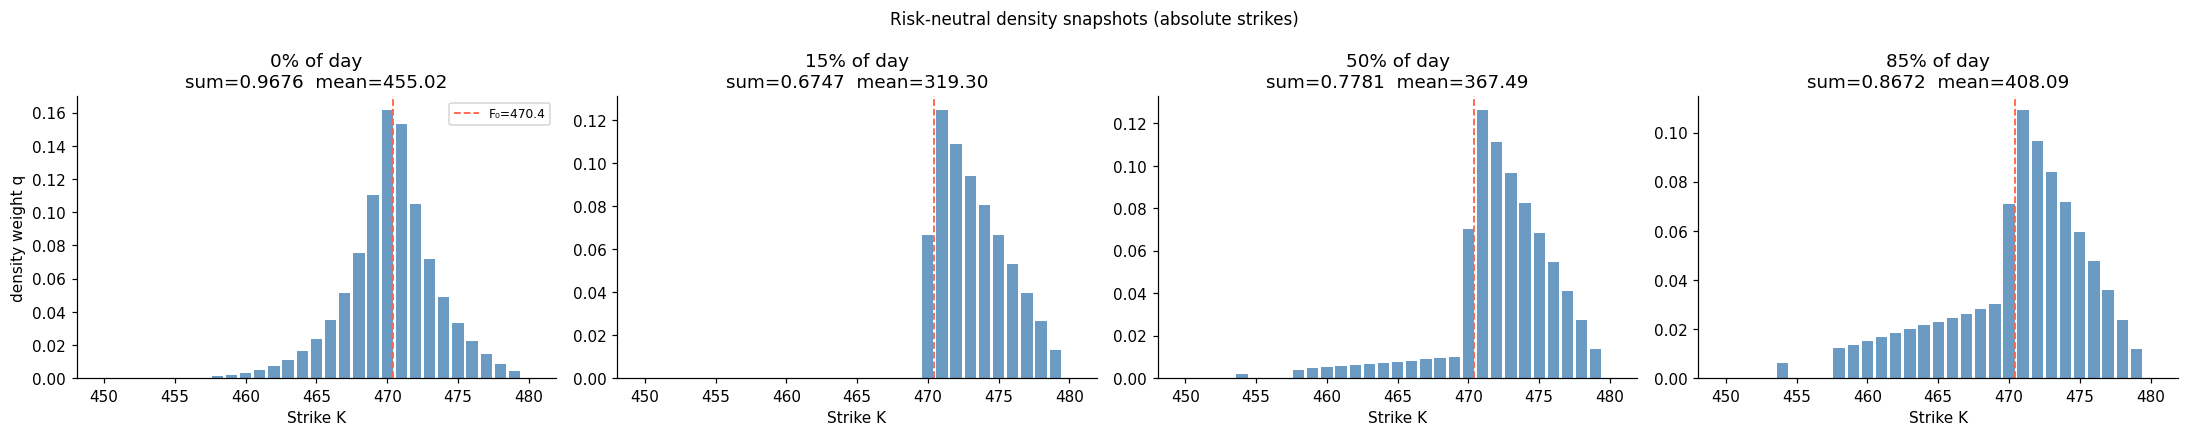

In [113]:
valid_mask = np.isfinite(neg_mass)
snap_fracs = [0.00, 0.15, 0.50, 0.85]
snap_idxs = [np.where(valid_mask)[0][int(p * valid_mask.sum())] for p in snap_fracs]

F_0_val = float((q_bar_0_jax * ak_jax).sum())
bar_w = 0.8 * np.min(np.diff(anchor_Ks))

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, idx, frac in zip(axes, snap_idxs, snap_fracs):
    q = Q_arr[idx]
    ax.bar(anchor_Ks, q, width=bar_w, color="steelblue", alpha=0.8)
    ax.axvline(F_0_val, color="tomato", lw=1.2, ls="--", label=f"F₀={F_0_val:.1f}")
    mart = np.dot(q, anchor_Ks)
    ax.set_title(f"{frac:.0%} of day\nsum={q.sum():.4f}  mean={mart:.2f}")
    ax.set_xlabel("Strike K")
    if ax is axes[0]:
        ax.set_ylabel("density weight q")
        ax.legend(fontsize=8)

fig.suptitle("Risk-neutral density snapshots (absolute strikes)", fontsize=11)
plt.tight_layout()
plt.show()

---
## Section 4 — State Evolution

### 4a. DLV heatmap (anchor × time)

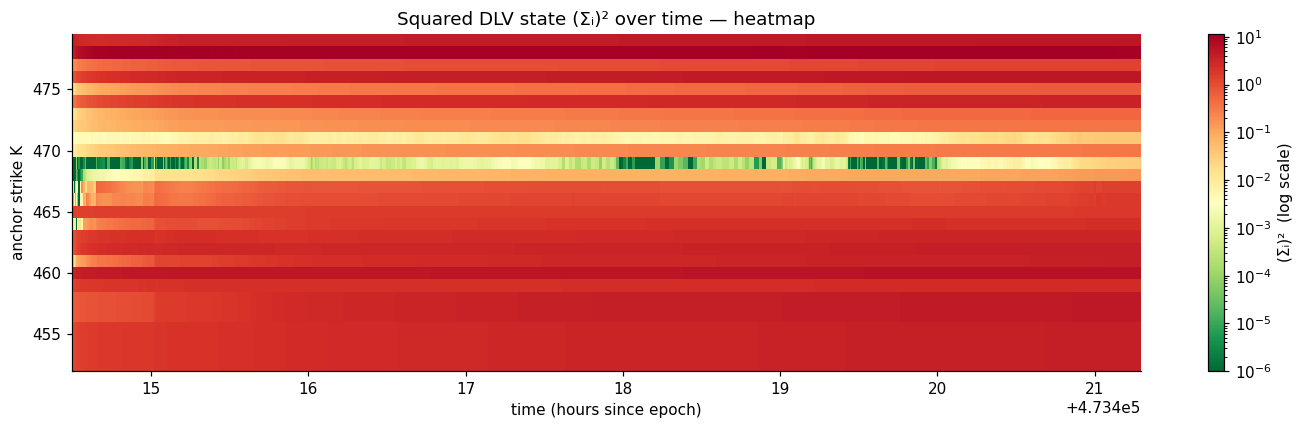

In [114]:
# Subsample to at most 500 time points for clarity
stride = max(1, len(X) // 500)
X_sub = X[::stride]  # (n_time, n_state)
ts_sub = ts_state[::stride]

# Interior anchors K[1]…K[N-2] (n_state = N-2)
interior_Ks = anchor_Ks[1:-1]
Sigma_sq_grid = X_sub.T  # (n_state, n_time) — values are already (Σᵢ)²

fig, ax = plt.subplots(figsize=(13, 4))
im = ax.pcolormesh(
    ts_sub,
    interior_Ks,
    Sigma_sq_grid,
    cmap="RdYlGn_r",
    norm=mcolors.LogNorm(
        vmin=max(Sigma_sq_grid[Sigma_sq_grid > 0].min(), 1e-6),
        vmax=Sigma_sq_grid.max(),
    ),
)
plt.colorbar(im, ax=ax, label="(Σᵢ)²  (log scale)")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("anchor strike K")
ax.set_title("Squared DLV state (Σᵢ)² over time — heatmap")
plt.tight_layout()
plt.show()

### 4b. Density weight q heatmap (anchor × time)

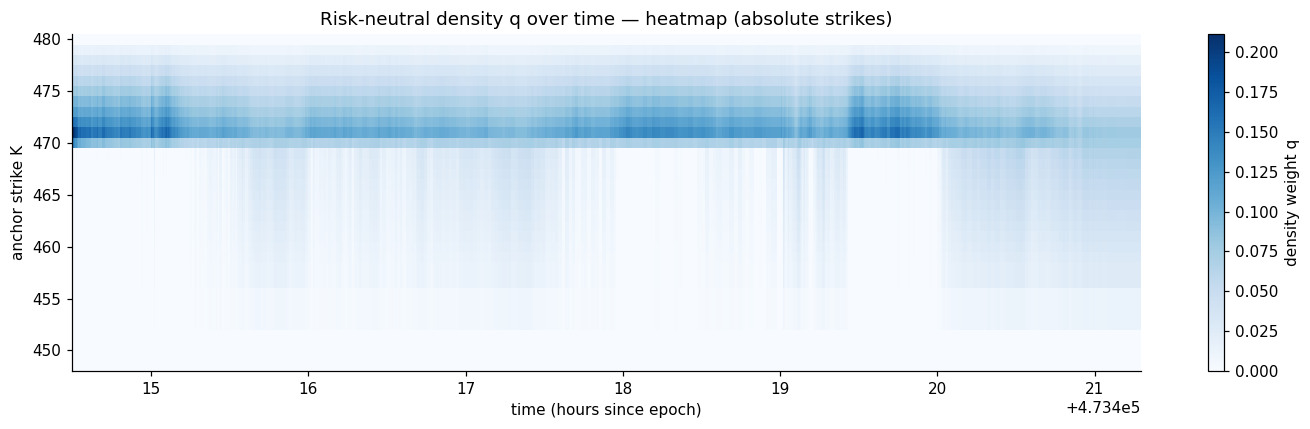

In [115]:
Q_sub = Q_arr[::stride].T  # (N, n_time)

fig, ax = plt.subplots(figsize=(13, 4))
im2 = ax.pcolormesh(ts_sub, anchor_Ks, Q_sub, cmap="Blues", vmin=0)
plt.colorbar(im2, ax=ax, label="density weight q")
ax.set_xlabel("time (hours since epoch)")
ax.set_ylabel("anchor strike K")
ax.set_title("Risk-neutral density q over time — heatmap (absolute strikes)")
plt.tight_layout()
plt.show()